<a href="https://colab.research.google.com/github/Sara4h/neural-pong-world-model/blob/main/Neural_Pong_World_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from tqdm.auto import tqdm

np.random.seed(42)
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)


Using device: cuda


In [2]:

class Pong:
    def __init__(self):
        self.size = 40
        self.paddle_height = 8
        self.reset()

    def reset(self):
        self.player_y = 16
        self.opponent_y = 16
        self.ball_x = 20
        self.ball_y = 20

        self.vx = np.random.choice([-1, 1])
        self.vy = np.random.choice([-1, 1])

        return self.render()

    def step(self, action):

        # Player movement
        if action == 1:
            self.player_y -= 2
        elif action == 2:
            self.player_y += 2

        self.player_y = np.clip(
            self.player_y, 0, 32
        )

        # Automated opponent
        center = self.opponent_y + 4

        if self.ball_y < center:
            self.opponent_y -= 1
        elif self.ball_y > center:
            self.opponent_y += 1

        self.opponent_y = np.clip(
            self.opponent_y, 0, 32
        )

        # Move ball
        self.ball_x += self.vx
        self.ball_y += self.vy

        # Top and bottom wall collisions
        if self.ball_y <= 0 or self.ball_y >= 39:
            self.vy *= -1
            self.ball_y = np.clip(
                self.ball_y, 0, 39
            )

        # Left paddle collision
        if self.ball_x == 2 and self.vx < 0:
            if self.player_y <= self.ball_y < self.player_y + 8:
                self.vx = 1

        # Right paddle collision
        if self.ball_x == 37 and self.vx > 0:
            if self.opponent_y <= self.ball_y < self.opponent_y + 8:
                self.vx = -1

        # Reset if a player misses
        if self.ball_x < 0 or self.ball_x >= 40:
            return self.reset()

        return self.render()

    def render(self):
        frame = np.zeros((40, 40), dtype=np.uint8)

        # Left paddle
        frame[self.player_y:self.player_y + 8, 1] = 255

        # Right paddle
        frame[self.opponent_y:self.opponent_y + 8, 38] = 255

        # Ball
        frame[int(self.ball_y), int(self.ball_x)] = 255

        return frame

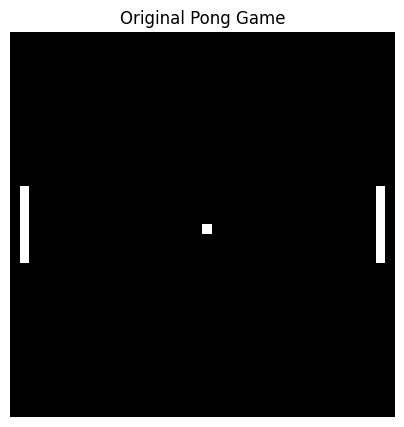

In [3]:

game = Pong()

frame = game.reset()

plt.figure(figsize=(5, 5))
plt.imshow(frame, cmap="gray", vmin=0, vmax=255)
plt.title("Original Pong Game")
plt.axis("off")
plt.show()

In [4]:

game = Pong()
demo_frames = []

for i in range(150):
    action = np.random.randint(0, 3)
    frame = game.step(action)
    demo_frames.append(frame)

fig, ax = plt.subplots(figsize=(4, 4))

im = ax.imshow(
    demo_frames[0],
    cmap="gray",
    vmin=0,
    vmax=255
)

ax.axis("off")

def update(i):
    im.set_data(demo_frames[i])
    return [im]

ani = FuncAnimation(
    fig,
    update,
    frames=len(demo_frames),
    interval=60,
    blit=True
)

plt.close(fig)
HTML(ani.to_jshtml())

In [5]:

NUM_FRAMES = 200_000

game = Pong()

frames = np.zeros(
    (NUM_FRAMES, 40, 40),
    dtype=np.uint8
)

actions = np.zeros(
    NUM_FRAMES - 1,
    dtype=np.uint8
)

frames[0] = game.reset()

for i in tqdm(range(NUM_FRAMES - 1)):

    if np.random.rand() < 0.6:
        center = game.player_y + 4

        if game.ball_y < center - 1:
            action = 1
        elif game.ball_y > center + 1:
            action = 2
        else:
            action = 0
    else:
        action = np.random.randint(0, 3)

    actions[i] = action
    frames[i + 1] = game.step(action)

print("Frames:", frames.shape)
print("Actions:", actions.shape)
print("Memory (MB):", frames.nbytes / 1e6)

  0%|          | 0/199999 [00:00<?, ?it/s]

Frames: (200000, 40, 40)
Actions: (199999,)
Memory (MB): 320.0


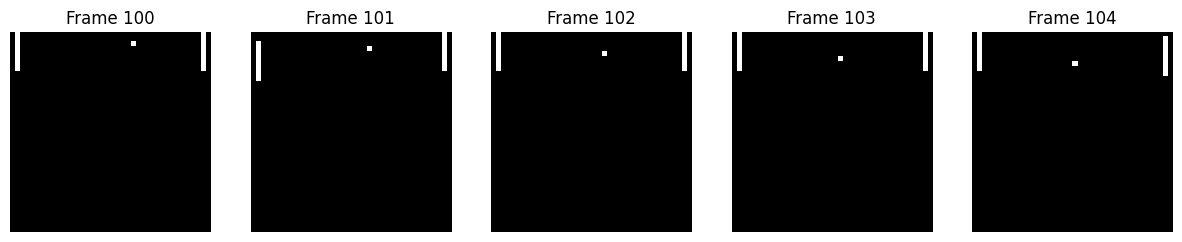

In [6]:

fig, axes = plt.subplots(1, 5, figsize=(15, 3))

for i in range(5):
    axes[i].imshow(
        frames[100 + i],
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axes[i].set_title(f"Frame {100 + i}")
    axes[i].axis("off")

plt.show()

In [7]:

class PongDataset(Dataset):

    def __init__(self, frames, actions):
        self.frames = frames
        self.actions = actions

    def __len__(self):
        return len(self.frames) - 4

    def __getitem__(self, idx):

        x = torch.from_numpy(
            self.frames[idx:idx + 4]
        ).float() / 255.0

        action = int(self.actions[idx + 3])

        action_map = torch.zeros(3, 40, 40)
        action_map[action] = 1.0

        x = torch.cat([x, action_map], dim=0)

        y = torch.from_numpy(
            self.frames[idx + 4]
        ).float().unsqueeze(0) / 255.0

        return x, y


# Separate training and validation data
split = int(len(frames) * 0.9)

train_dataset = PongDataset(
    frames[:split],
    actions[:split - 1]
)

val_dataset = PongDataset(
    frames[split:],
    actions[split:]
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

x, y = train_dataset[0]

print("Input shape:", x.shape)
print("Target shape:", y.shape)

Input shape: torch.Size([7, 40, 40])
Target shape: torch.Size([1, 40, 40])


In [8]:

class PongWorldModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(

            nn.Conv2d(7, 32, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=2, dilation=2),
            nn.ReLU(),

            nn.Conv2d(64, 32, kernel_size=3, padding=4, dilation=4),
            nn.ReLU(),

            nn.Conv2d(32, 1, kernel_size=3, padding=1)
        )

    def forward(self, x):
        return self.network(x)


model = PongWorldModel().to(device)

print(model)

print(
    "Total parameters:",
    sum(p.numel() for p in model.parameters())
)

PongWorldModel(
  (network): Sequential(
    (0): Conv2d(7, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(2, 2), dilation=(2, 2))
    (5): ReLU()
    (6): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(4, 4), dilation=(4, 4))
    (7): ReLU()
    (8): Conv2d(32, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
)
Total parameters: 76225


In [9]:

criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor([30.0], device=device)
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 5

train_losses = []
val_losses = []

In [10]:

for epoch in range(EPOCHS):

    model.train()
    running_loss = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS}"
    )

    for x, y in progress:

        x = x.to(device)
        y = y.to(device)

        # Add noise to image channels only
        noisy_frames = (
            x[:, :4] +
            torch.randn_like(x[:, :4]) * 0.03
        ).clamp(0, 1)

        x = torch.cat(
            [noisy_frames, x[:, 4:]],
            dim=1
        )

        optimizer.zero_grad()

        predictions = model(x)
        loss = criterion(predictions, y)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        progress.set_postfix(loss=loss.item())

    train_loss = running_loss / len(train_loader)
    train_losses.append(train_loss)

    # Validation
    model.eval()
    validation_loss = 0

    with torch.no_grad():
        for x, y in val_loader:

            x = x.to(device)
            y = y.to(device)

            predictions = model(x)

            validation_loss += criterion(
                predictions, y
            ).item()

    val_loss = validation_loss / len(val_loader)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1}: "
        f"Train Loss = {train_loss:.6f}, "
        f"Val Loss = {val_loss:.6f}"
    )

Epoch 1/5:   0%|          | 0/2813 [00:00<?, ?it/s]

Epoch 1: Train Loss = 0.022659, Val Loss = 0.009060


Epoch 2/5:   0%|          | 0/2813 [00:00<?, ?it/s]

Epoch 2: Train Loss = 0.008010, Val Loss = 0.008439


Epoch 3/5:   0%|          | 0/2813 [00:00<?, ?it/s]

Epoch 3: Train Loss = 0.007042, Val Loss = 0.008186


Epoch 4/5:   0%|          | 0/2813 [00:00<?, ?it/s]

Epoch 4: Train Loss = 0.006504, Val Loss = 0.007622


Epoch 5/5:   0%|          | 0/2813 [00:00<?, ?it/s]

Epoch 5: Train Loss = 0.006186, Val Loss = 0.006862


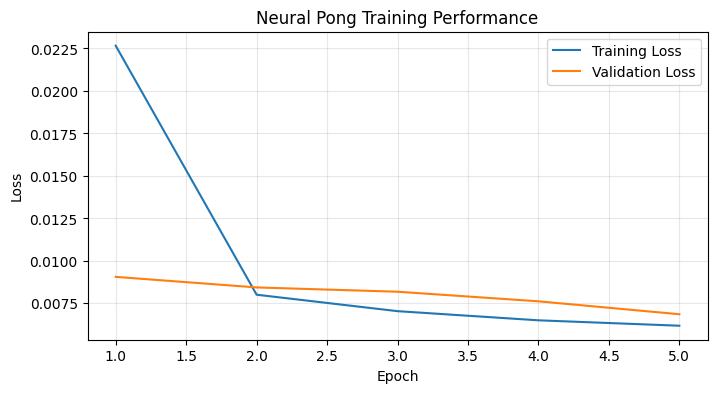

In [11]:

plt.figure(figsize=(8, 4))

plt.plot(
    range(1, EPOCHS + 1),
    train_losses,
    label="Training Loss"
)

plt.plot(
    range(1, EPOCHS + 1),
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Neural Pong Training Performance")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

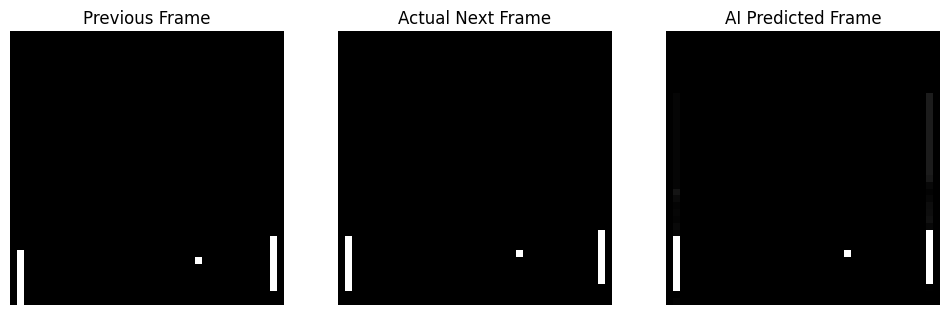

In [12]:

model.eval()

x, y = val_dataset[100]

with torch.no_grad():

    prediction = torch.sigmoid(
        model(x.unsqueeze(0).to(device))
    ).cpu().squeeze().numpy()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(x[3], cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Previous Frame")

axes[1].imshow(y.squeeze(), cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Actual Next Frame")

axes[2].imshow(prediction, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("AI Predicted Frame")

for ax in axes:
    ax.axis("off")

plt.show()

In [13]:

class NeuralPong:

    def __init__(self, model, initial_frames):

        self.model = model
        self.model.eval()

        self.history = torch.tensor(
            initial_frames,
            dtype=torch.float32
        ).to(device) / 255.0

    @torch.no_grad()
    def step(self, action):

        action_map = torch.zeros(
            3, 40, 40,
            device=device
        )

        action_map[action] = 1.0

        x = torch.cat(
            [self.history, action_map],
            dim=0
        ).unsqueeze(0)

        prediction = torch.sigmoid(
            self.model(x)
        ).squeeze(0)

        self.history = torch.cat(
            [self.history[1:], prediction],
            dim=0
        )

        return prediction.squeeze(0).cpu().numpy()

In [14]:

initial_frames = frames[split:split + 4]

neural_game = NeuralPong(
    model,
    initial_frames
)

generated_frames = []

for i in range(150):

    action = np.random.randint(0, 3)

    predicted_frame = neural_game.step(action)

    generated_frames.append(predicted_frame)


fig, ax = plt.subplots(figsize=(5, 5))

im = ax.imshow(
    generated_frames[0],
    cmap="gray",
    vmin=0,
    vmax=1
)

ax.set_title("Pong Inside a Neural Network")
ax.axis("off")

def update(i):
    im.set_data(generated_frames[i])
    return [im]

ani = FuncAnimation(
    fig,
    update,
    frames=len(generated_frames),
    interval=80,
    blit=True
)

plt.close(fig)
HTML(ani.to_jshtml())

In [15]:

import ipywidgets as widgets

from IPython.display import display, clear_output

neural_game = NeuralPong(
    model,
    frames[split:split + 4]
)

output = widgets.Output()

up_button = widgets.Button(description="↑ Up")
stay_button = widgets.Button(description="Stay")
down_button = widgets.Button(description="↓ Down")
reset_button = widgets.Button(description="Reset")

def draw_frame(frame):

    with output:
        clear_output(wait=True)

        plt.figure(figsize=(4, 4))
        plt.imshow(frame, cmap="gray", vmin=0, vmax=1)
        plt.axis("off")
        plt.show()
        plt.close()

def move(action):
    frame = neural_game.step(action)
    draw_frame(frame)

def reset_game(button):
    global neural_game

    neural_game = NeuralPong(
        model,
        frames[split:split + 4]
    )

    draw_frame(frames[split + 3] / 255.0)

up_button.on_click(lambda b: move(1))
stay_button.on_click(lambda b: move(0))
down_button.on_click(lambda b: move(2))
reset_button.on_click(reset_game)

display(
    widgets.HBox([
        up_button,
        stay_button,
        down_button,
        reset_button
    ]),
    output
)

draw_frame(frames[split + 3] / 255.0)

Output()

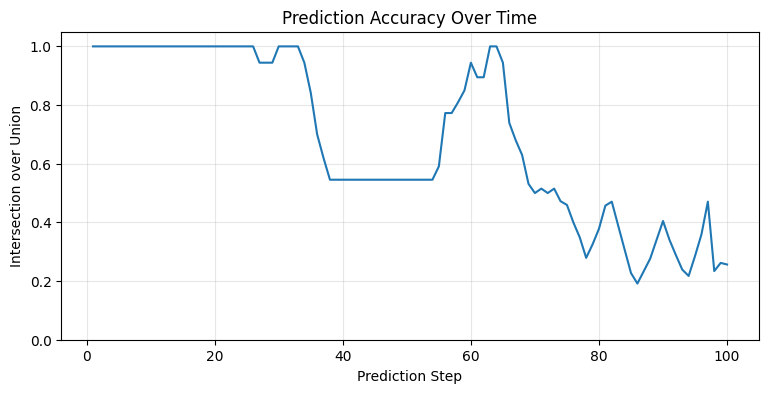

In [16]:

start = split + 100
steps = 100

neural_game = NeuralPong(
    model,
    frames[start:start + 4]
)

real_frames = []
predicted_frames = []
iou_scores = []

for i in range(steps):

    action = int(actions[start + 3 + i])

    predicted = neural_game.step(action)

    actual = frames[start + 4 + i] / 255.0

    real_frames.append(actual)
    predicted_frames.append(predicted)

    # Compare foreground pixels
    pred_mask = predicted > 0.5
    real_mask = actual > 0.5

    intersection = np.logical_and(
        pred_mask, real_mask
    ).sum()

    union = np.logical_or(
        pred_mask, real_mask
    ).sum()

    iou = intersection / max(union, 1)

    iou_scores.append(iou)

plt.figure(figsize=(9, 4))
plt.plot(range(1, steps + 1), iou_scores)
plt.xlabel("Prediction Step")
plt.ylabel("Intersection over Union")
plt.title("Prediction Accuracy Over Time")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.show()

In [17]:

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

real_im = axes[0].imshow(
    real_frames[0],
    cmap="gray",
    vmin=0,
    vmax=1
)

pred_im = axes[1].imshow(
    predicted_frames[0],
    cmap="gray",
    vmin=0,
    vmax=1
)

axes[0].set_title("Real Pong")
axes[1].set_title("Neural Network Pong")

for ax in axes:
    ax.axis("off")

def update(i):

    real_im.set_data(real_frames[i])
    pred_im.set_data(predicted_frames[i])

    return [real_im, pred_im]

ani = FuncAnimation(
    fig,
    update,
    frames=steps,
    interval=100,
    blit=True
)

plt.close(fig)
HTML(ani.to_jshtml())

In [18]:

torch.save(
    model.state_dict(),
    "pong_world_model.pth"
)

from google.colab import files

files.download("pong_world_model.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>